# PRÁCTICA 3: SISTEMAS DE APOYO A LA DECISIÓN CLÍNICA CON PERCEPTRÓN

### TAREA 1: CARGA Y EXPLORACIÓN DE DATOS

Realizamos la carga del JSON de configuración y del CSV de nuestro grupo (grupo05).

In [1]:
import json

GRUPO = 5  
#Tenemos que subir un nivel para entrar en la carpeta de datos
config_path = f"../datos/grupo_{GRUPO:02d}_config.json"
with open(config_path, encoding="utf-8") as f:
    config = json.load(f)

print("Número de sujetos:", config["n_sujetos"])
print("Patologías:", config["patologias"])
print("Distribución:", config["distribucion_patologias"])
print("Partición:", config["nota_particion"])
print("\nAviso:", config["aviso"])

Número de sujetos: 1000
Patologías: ['infeccion_respiratoria', 'infeccion_urinaria', 'gastroenteritis', 'insuficiencia_cardiaca', 'exacerbacion_respiratoria']
Distribución: {'exacerbacion_respiratoria': 191, 'gastroenteritis': 201, 'infeccion_respiratoria': 209, 'infeccion_urinaria': 197, 'insuficiencia_cardiaca': 202}
Partición: El dataset NO incluye partición predefinida. El alumnado debe dividir los datos en entrenamiento, validación y prueba, justificando los porcentajes elegidos.

Aviso: Datos exclusivamente docentes. No representan criterios clínicos reales. No utilizar para diagnóstico.


In [2]:
import pandas as pd

datos_path = f"../datos/grupo_{GRUPO:02d}_datos.csv"
df = pd.read_csv(datos_path)

print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (1000, 31)


,edad,sexo_masculino,fiebre,tos,disnea,frecuencia_respiratoria,saturacion_o2,disuria,polaquiuria,nitritos,...,tabaquismo,gasometria_ph,pcr,leucocitos_sangre,glucosa,creatinina,temperatura,tas,tad,patologia
0,90,0,0.0,0.0,0.0,16,95.7,0.0,0.0,0.0,...,0.0,7.346,37.9,12.94,82,0.91,38.1,129,74,gastroenteritis
1,27,1,1.0,1.0,0.0,16,100.0,0.0,0.0,0.0,...,0.0,7.440,67.2,10.65,105,0.67,37.2,106,71,gastroenteritis
2,58,0,0.0,1.0,1.0,18,96.0,0.0,0.0,0.0,...,0.0,7.403,69.6,11.61,77,0.50,39.2,115,65,infeccion_respiratoria
3,31,0,0.0,0.0,0.0,16,90.5,0.0,0.0,0.0,...,0.0,7.377,3.4,9.45,128,1.30,38.0,95,75,gastroenteritis
4,64,0,0.0,1.0,1.0,28,87.0,0.0,0.0,0.0,...,0.0,7.343,22.6,11.18,86,1.24,37.7,117,88,exacerbacion_respiratoria


Dimensiones del dataset: (1000, 31), por tanto las filas del CSV coinciden con el número de sujetos del JSON

Generamos tres visualizaciones que exploren la relación entre variables del csv y patología (histogramas, boxplots o diagramas de barras para variables binarias).

Realizamos un diagrama de barras apilado que relaciones el tabaquismo y patología:

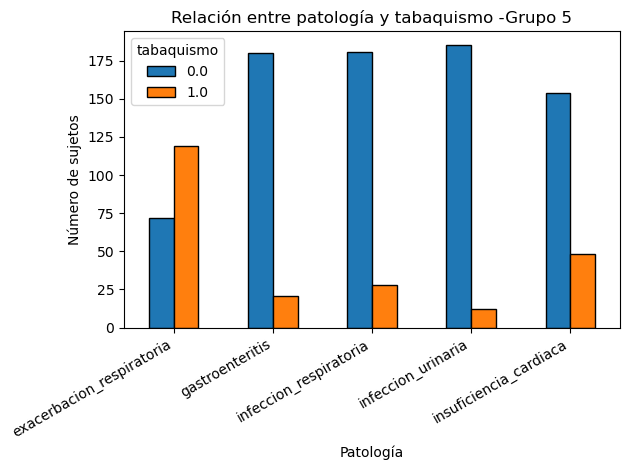

In [3]:
import matplotlib.pyplot as plt

df.value_counts(["patologia", "tabaquismo"]).unstack().plot(kind="bar",  edgecolor="black")

plt.title("Relación entre patología y tabaquismo -Grupo " +str(GRUPO))
plt.xlabel("Patología")
plt.ylabel("Número de sujetos")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()


Podemos comprobar que la relación entre patología y tabaquismo es directa en el caso de la excerbacion_respiratoria y el tabaquismo. En el resto de patologías, el tabaquismo no tiene mucha relación.

Ahora realizamos un boxplot entre patología y glucosa.

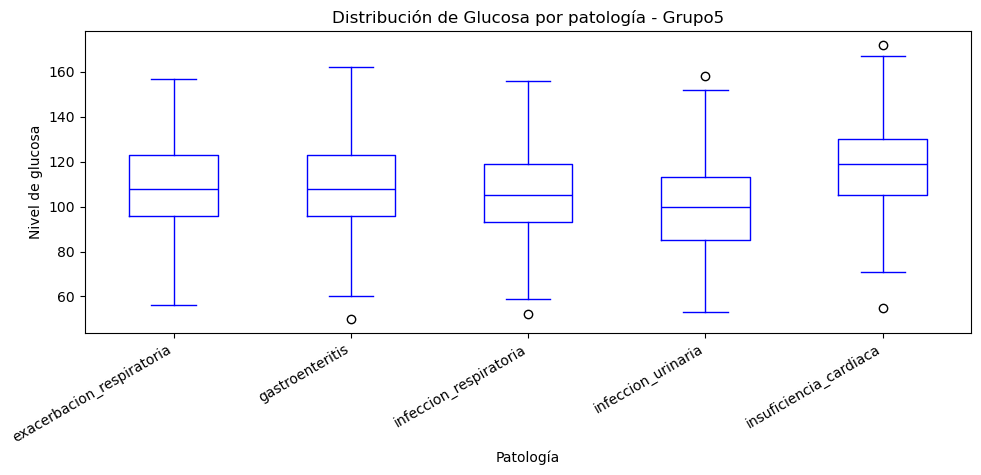

In [4]:
import matplotlib.pyplot as plt

df.boxplot(column="glucosa", by="patologia", figsize=(10, 5), grid=False, color="blue")

plt.title("Distribución de Glucosa por patología - Grupo" + str(GRUPO))
plt.suptitle("") 
plt.xlabel("Patología")
plt.ylabel("Nivel de glucosa")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

La insufiencia_cardiaca es la patología con el nivel de glucosa más alto.
La infeccion_urinaria presenta los niveles generales de glucosa más bajos en su rango intercuartílico.
Los outliers representan a pacientes con niveles de glucosa atípicos que se salen del comportamiento general del grupo.

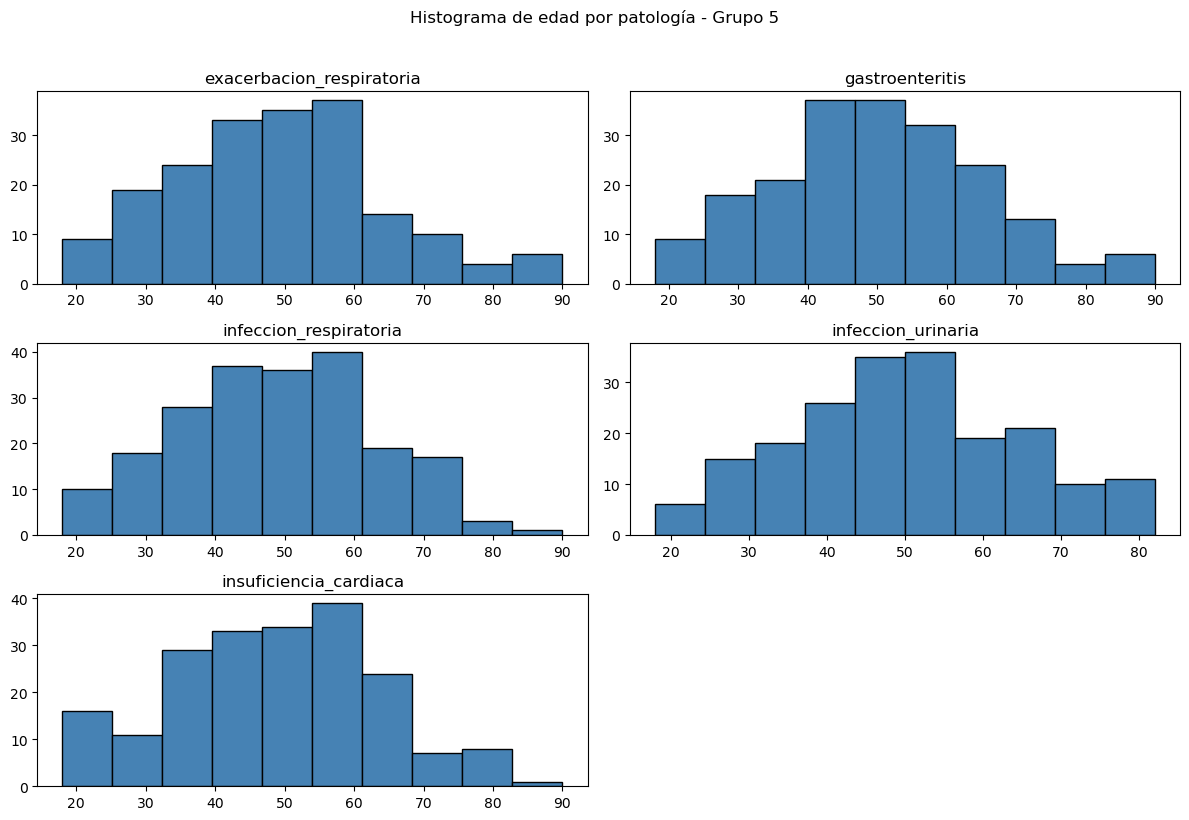

In [5]:
import matplotlib.pyplot as plt

df.hist(column="edad", by="patologia", figsize=(12, 8), color="steelblue", edgecolor="black", grid=False, xrot=0)


plt.suptitle("Histograma de edad por patología - Grupo " + str(GRUPO), y=1.02)
plt.tight_layout()
plt.show()

Estos histogramas representan en el eje x la edad de los pacientes y en el eje y la frecuencia de los mismos. 
En todos podemos ver que la mayoría de personas que sufren estas patologías se encuentran entre los 40-60 años.

### TAREA 2: PREPARACIÓN DE LOS DATOS

División de los datos de entrenamiento, validación y prueba usando train_test_split

Tenemos que tener en cuenta que la variable patología es la variable objetivo.

In [6]:
from sklearn.model_selection import train_test_split

#variables de entrada sin patología
X= df.drop(columns=["patologia"])
#variable objetivo
y= df["patologia"]

#Primera división: 60 % entrenamientoy 40% restante(cada uno con su etiqueta)
X_entrenamiento, X_resto, y_entrenamiento, y_resto = train_test_split(
    X, y, 
    test_size=0.40, 
    stratify=y, 
    random_state=21
)
#Segunda división: 20% validación y 20 % prueba
X_validacion, X_prueba, y_validacion, y_prueba = train_test_split(
    X_resto, y_resto, 
    test_size=0.50, 
    stratify=y_resto, 
    random_state=21
)

In [7]:
#Tamaño de nuestro data set (número de sujetos)
print("Número total de sujetos:", config["n_sujetos"])
#Número de sujetos que quedan en cada subconjunto después de la división
print("Número de sujetos en el conjunto de entrenamiento:", len(X_entrenamiento))
print("Número de sujetos en el conjunto de validación:", len(X_validacion))
print("Número de sujetos en el conjunto de prueba:", len(X_prueba))


Número total de sujetos: 1000
Número de sujetos en el conjunto de entrenamiento: 600
Número de sujetos en el conjunto de validación: 200
Número de sujetos en el conjunto de prueba: 200


Hemos elegido estos porcentajes, reservando una mayor proporción para los datos de entrenamiento para que el modelo disponga de ejemplos suficientes para aprender los patrones asociados a distintas patologías.

El 20% de validación permitirá comparar modelos y ajustar sus hiperparámetros durante el desarrollo. Por otro lado, el 20% reservado para prueba permitirá evaluar el rendimiento final del modelo utilizando datos que no han intervenido en las otras etapas. Este subconjunto es especialmente importante, ya que determinará la fiabilidad de la evaluación final.

Hemos utilizado y= df["patologia"], stratify=y para mantener aproximadamente las proporciones originales de cada patología en los tres subconjuntos, evitando que alguna clase quede ausente.


### TAREA 3: CDS BASADO EN REGLAS (SISTEMA DE PUNTUACIÓN)

Implementamos el sistema basado en reglas. Este sistema no aprende de los datos, es decir, somos nosotros quienes decidimos a mano cuántos puntos da cada variable a cada patología. Para cada paciente se calcula una puntuación por patología, $s_c = b_c + \sum_j w_{c,j}\,x_j$, usando los datos sin escalar y se recomienda la patología que más puntos tenga. Si las dos primeras están muy igualadas (la diferencia es menor que un umbral), el sistema responde `indeterminado`.

Evaluamos el modelo usando el conjunto de entrenamiento para generar la matriz de confusión y probar cómo afecta cambiar el umbral de los casos indeterminados.

In [8]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

columnas_X = X_entrenamiento.columns.tolist()
n_vars = len(columnas_X)
PATOLOGIAS = config["patologias"]

#Entrenamiento solo para explorar
df_train = X_entrenamiento.copy()
df_train["patologia"] = y_entrenamiento

# Media de cada variable en cada patología (filas = variables, columnas = patologías)
medias_train = df_train.groupby("patologia")[columnas_X].mean().T[PATOLOGIAS]
medias_train.round(2)


patologia,infeccion_respiratoria,infeccion_urinaria,gastroenteritis,insuficiencia_cardiaca,exacerbacion_respiratoria
edad,49.30,49.51,50.36,47.91,48.63
sexo_masculino,0.49,0.59,0.51,0.54,0.43
fiebre,0.77,0.26,0.36,0.23,0.43
tos,0.78,0.11,0.09,0.25,0.74
disnea,0.54,0.10,0.12,0.76,0.90
frecuencia_respiratoria,21.46,16.32,16.86,23.15,24.87
saturacion_o2,93.07,96.78,96.65,90.23,87.11
disuria,0.03,0.93,0.04,0.02,0.03
polaquiuria,0.02,0.86,0.05,0.02,0.03
nitritos,0.03,0.91,0.04,0.02,0.04


#### Pesos y sesgos

Cada fila de `W_cds` es una patología (en el orden de `PATOLOGIAS`) y cada columna es una variable (en el orden de `columnas_X`). 
Lo rellenamos con un diccionario por patología para asignar cada peso a su variable por el nombre.

In [9]:
#Matriz de pesos (5 patologías x n variables) y vector de sesgos (uno por patología)
W_cds = np.zeros((5, n_vars))
B_cds = np.zeros(5)

# Diccionario que asocia los pesos por patología.
pesos_dict = {
    0: {'fiebre': 2.0, 'tos': 2.0, 'pcr': 0.05, 'leucocitos_sangre': 0.5, 'temperatura': 0.5, 'saturacion_o2': -0.1},
    1: {'disuria': 2.0, 'polaquiuria': 2.0, 'nitritos': 3.0, 'leucocitos_orina': 0.05, 'dolor_lumbar': 1.0},
    2: {'diarrea': 3.0, 'vomitos': 3.0, 'dolor_abdominal': 2.0, 'sodio': -0.1, 'potasio': -0.5},
    3: {'edemas': 3.0, 'disnea': 1.0, 'frecuencia_cardiaca': 0.05, 'peso_kg': 0.05, 'creatinina': 2.0, 'saturacion_o2': -0.1},
    4: {'sibilancias': 3.0, 'tabaquismo': 1.5, 'disnea': 1.5, 'frecuencia_respiratoria': 0.2, 'gasometria_ph': -2.0}
}

# Rellena la matriz W_cds emparejando la variable con su columna
for clase_idx, pesos in pesos_dict.items():
    for var, peso in pesos.items():
        var_idx = columnas_X.index(var)
        W_cds[clase_idx, var_idx] = peso

# Vector de sesgos 
B_cds = np.array([-18.0, -1.0, 15.0, -1.5, 10.0])

#Tabla resumen
tabla_W = pd.DataFrame(W_cds, index=PATOLOGIAS, columns=columnas_X).T
tabla_W = tabla_W[(tabla_W != 0).any(axis=1)]
tabla_W.loc["SESGO"] = B_cds
tabla_W

,infeccion_respiratoria,infeccion_urinaria,gastroenteritis,insuficiencia_cardiaca,exacerbacion_respiratoria
fiebre,2.00,0.00,0.0,0.00,0.0
tos,2.00,0.00,0.0,0.00,0.0
disnea,0.00,0.00,0.0,1.00,1.5
frecuencia_respiratoria,0.00,0.00,0.0,0.00,0.2
saturacion_o2,-0.10,0.00,0.0,-0.10,0.0
disuria,0.00,2.00,0.0,0.00,0.0
polaquiuria,0.00,2.00,0.0,0.00,0.0
nitritos,0.00,3.00,0.0,0.00,0.0
leucocitos_orina,0.00,0.05,0.0,0.00,0.0
dolor_lumbar,0.00,1.00,0.0,0.00,0.0


#### Evaluación sobre el conjunto de entrenamiento 


In [10]:
import numpy as np

PATOLOGIAS = config["patologias"]

# ---- Definir aquí los pesos y sesgos del CDS ----
# W_cds: matriz (5 x n_variables), B_cds: vector (5,)
n_vars = len(columnas_X)
W_cds = np.zeros((5, n_vars))   # sustituir por los pesos definidos
B_cds = np.zeros(5)             # sustituir por los sesgos definidos


def cds_puntuacion(x, W, B):
    """Calcula las puntuaciones del CDS para un sujeto (datos sin escalar)."""
    return B + W @ x


def cds_predice(x, W, B, patologias, umbral_indeterminado=1.0):
    """Devuelve la patología recomendada y las dos con mayor puntuación.
    Si la diferencia entre la primera y la segunda es menor que
    umbral_indeterminado, devuelve 'indeterminado'.
    """
    puntuaciones = cds_puntuacion(x, W, B)
    orden = np.argsort(puntuaciones)[::-1]
    top2 = [patologias[i] for i in orden[:2]]
    if puntuaciones[orden[0]] - puntuaciones[orden[1]] < umbral_indeterminado:
        prediccion = "indeterminado"
    else:
        prediccion = top2[0]
    return prediccion, top2, puntuaciones

Efecto del umbral de indeterminacion

In [33]:
umbrales_a_probar = [0.5, 1.5, 2.0]

for u in umbrales_a_probar:
    preds_u = [cds_predice(x, W_cds, B_cds, PATOLOGIAS, umbral_indeterminado=u)[0] for x in X_entrenamiento.values]
    
    indet_u = preds_u.count("indeterminado")
    clasif_u = total - indet_u
    aciertos_u = sum(1 for p, y in zip(preds_u, y_train_list) if p == y and p != "indeterminado")
    
    acc_global = aciertos_u / total
    acc_clasif = (aciertos_u / clasif_u) if clasif_u > 0 else 0
    
    print(f"Umbral: {u} | Indeterminados: {indet_u} | Exactitud Global: {acc_global:.3f} | Exactitud Clasificados: {acc_clasif:.3f}")

Umbral: 0.5 | Indeterminados: 600 | Exactitud Global: 0.000 | Exactitud Clasificados: 0.000
Umbral: 1.5 | Indeterminados: 600 | Exactitud Global: 0.000 | Exactitud Clasificados: 0.000
Umbral: 2.0 | Indeterminados: 600 | Exactitud Global: 0.000 | Exactitud Clasificados: 0.000
